In [7]:
import re
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import gridspec
import pandas as pd

plt.rcParams['figure.dpi'] = 120
plt.rcParams['savefig.dpi'] = 200

COLOR_CYCLE = [
    '#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd',
    '#8c564b', '#e377c2', '#7f7f7f', '#bcbd22', '#17becf'
]

In [9]:
# ===================== 配置：选择要可视化的 log =====================
log_paths = [
    '/root/diffusion_for_represent_learning/Segmentation/mmsegmentation/work_dirs/ablation_experiment/baseline_nothing_36k/20260923_071938/20260923_071938.log',
    '/root/diffusion_for_represent_learning/Segmentation/mmsegmentation/work_dirs/ablation_experiment/diffae_36k/20260923_121654/20260923_121654.log',
    '/root/diffusion_for_represent_learning/Segmentation/mmsegmentation/work_dirs/ablation_experiment/diffae_tsampler_pos_36k/20260924_173032/20260924_173032.log',
    ]
log_labels = ['baseline', 'diffae', 'tsample_pos']
# ===================================================================

train_iter_pattern = re.compile(r'Iter\(train\)\s*\[\s*(\d+)/(\d+)\]')
kv_pattern = re.compile(r'([A-Za-z_][\w.]*):\s*(-?[\d.]+(?:[eE][+-]?\d+)?)')

val_pattern = re.compile(
    r'Iter\(val\)\s*\[\d+/\d+\]\s+aAcc:\s*([\deE+-.]+)\s+'
    r'mIoU:\s*([\deE+-.]+)\s+mAcc:\s*([\deE+-.]+)'
)

all_logs = []

for path, label in zip(log_paths, log_labels):
    with open(path, 'r', encoding='utf-8') as f:
        lines = f.readlines()

    # ---- train：通用 key-value 解析，兼容 baseline / diffae / 任意新字段 ----
    rows = []
    last_train_iter = None
    val_iters, val_aAcc, val_mIoU, val_mAcc = [], [], [], []

    for line in lines:
        mt = train_iter_pattern.search(line)
        if mt is not None:
            last_train_iter = int(mt.group(1))
            row = {'iter': int(mt.group(1)), 'total': int(mt.group(2))}
            row.update({k: float(v) for k, v in kv_pattern.findall(line)})
            rows.append(row)
            continue

        mv = val_pattern.search(line)
        if mv is not None and last_train_iter is not None:
            val_iters.append(last_train_iter)
            val_aAcc.append(float(mv.group(1)))
            val_mIoU.append(float(mv.group(2)))
            val_mAcc.append(float(mv.group(3)))

    df = pd.DataFrame(rows)

    # 派生列：seg 部分总损失 = 总 loss - diffae 分支 loss（baseline 无该字段，按 0 处理）
    if 'loss_diffae' not in df.columns:
        df['loss_diffae'] = np.nan
    df['seg_total'] = df['loss'] - df['loss_diffae'].fillna(0)

    log_info = {
        'label': label,
        'df': df,
        'val_iters': np.array(val_iters),
        'val_aAcc': np.array(val_aAcc),
        'val_mIoU': np.array(val_mIoU),
        'val_mAcc': np.array(val_mAcc),
    }
    all_logs.append(log_info)

    n_diffae = df['loss_diffae'].notna().sum()
    print(f"[{label}] train={len(df)} iters, val={len(val_mIoU)} times, "
          f"loss_diffae 行数={n_diffae}")
    print(f"         val_iters = {list(val_iters)}")

[baseline] train=720 iters, val=6 times, loss_diffae 行数=0
         val_iters = [6000, 12000, 18000, 24000, 30000, 36000]
[diffae] train=720 iters, val=3 times, loss_diffae 行数=720
         val_iters = [12000, 24000, 36000]
[tsample_pos] train=720 iters, val=3 times, loss_diffae 行数=720
         val_iters = [12000, 24000, 36000]


/tmp/ipykernel_96246/1454195382.py:27: UserWarning: Glyph 20027 (\N{CJK UNIFIED IDEOGRAPH-4E3B}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_96246/1454195382.py:27: UserWarning: Glyph 20998 (\N{CJK UNIFIED IDEOGRAPH-5206}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_96246/1454195382.py:27: UserWarning: Glyph 21106 (\N{CJK UNIFIED IDEOGRAPH-5272}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_96246/1454195382.py:27: UserWarning: Glyph 36741 (\N{CJK UNIFIED IDEOGRAPH-8F85}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_96246/1454195382.py:27: UserWarning: Glyph 21161 (\N{CJK UNIFIED IDEOGRAPH-52A9}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_96246/1454195382.py:27: UserWarning: Glyph 24635 (\N{CJK UNIFIED IDEOGRAPH-603B}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_96246/1454195382.py:27: UserWarning: Glyph 25439 (\N{CJK UNIFIED IDEOGRAP

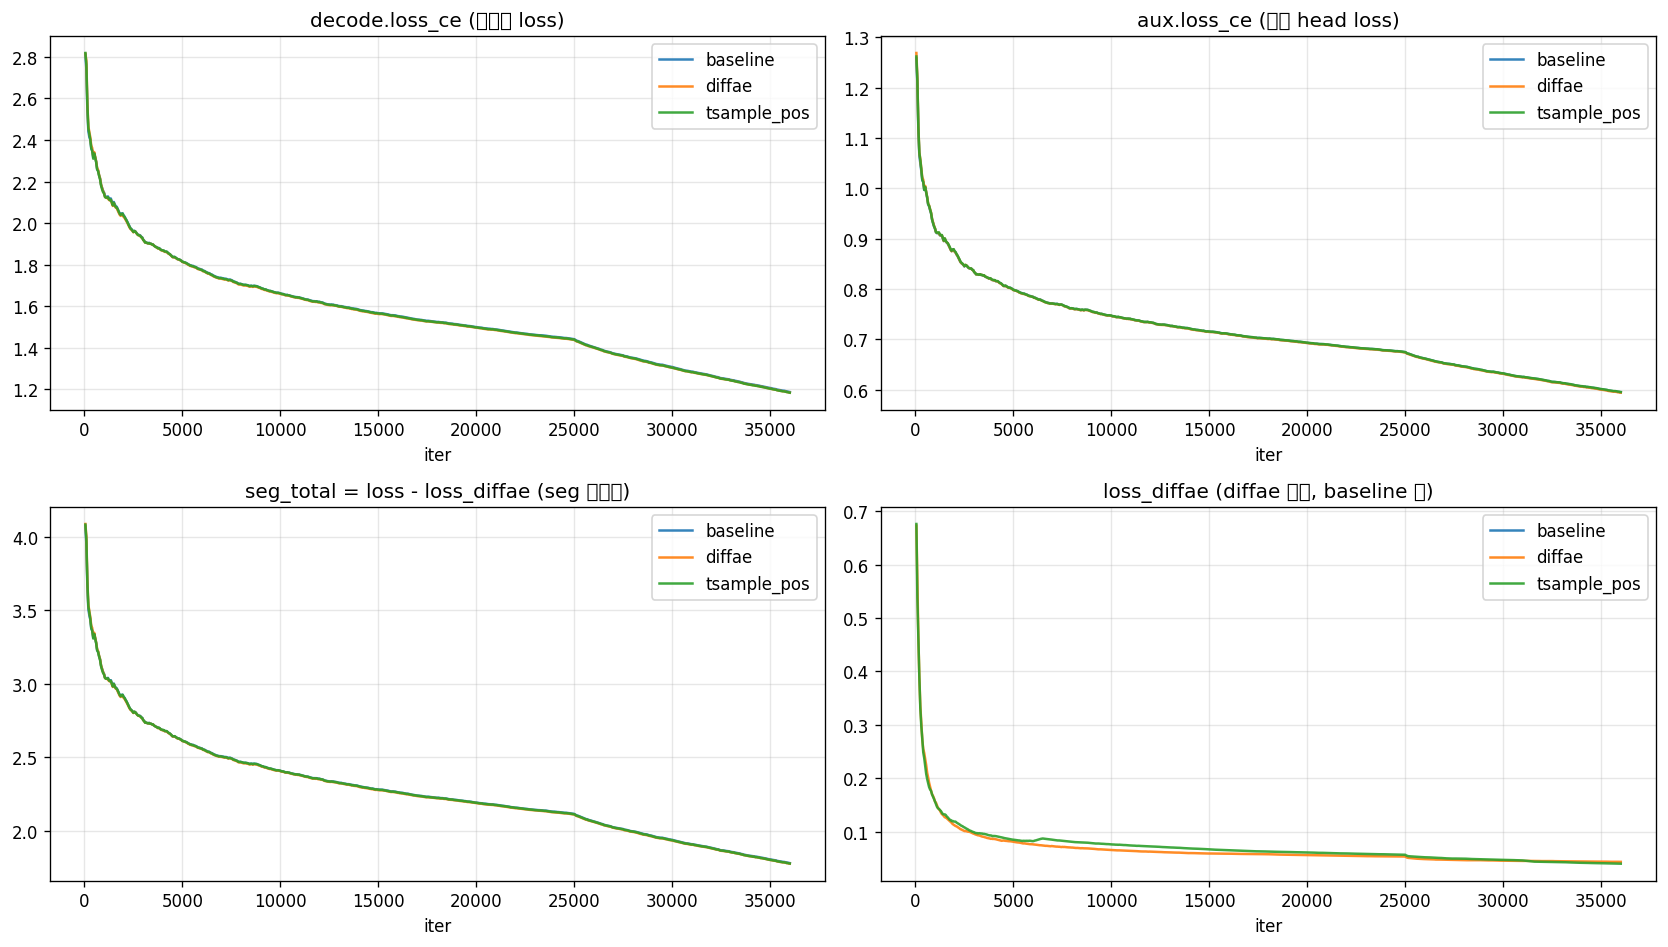

In [10]:
# ===================== 下游 seg loss 曲线 =====================
def smooth(x, w=500):
    """滑动平均平滑，w 越小越贴近原始曲线"""
    return pd.Series(x).rolling(w, min_periods=1).mean()

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
panels = [
    ('decode.loss_ce', 'decode.loss_ce (主分割 loss)'),
    ('aux.loss_ce',    'aux.loss_ce (辅助 head loss)'),
    ('seg_total',      'seg_total = loss - loss_diffae (seg 总损失)'),
    ('loss_diffae',    'loss_diffae (diffae 分支, baseline 无)'),
]

for ax, (col, title) in zip(axes.flat, panels):
    for i, log in enumerate(all_logs):
        df = log['df']
        if col not in df.columns:
            continue
        ax.plot(df['iter'], smooth(df[col]),
                color=COLOR_CYCLE[i % len(COLOR_CYCLE)],
                label=log['label'], alpha=0.9)
    ax.set_title(title)
    ax.set_xlabel('iter')
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

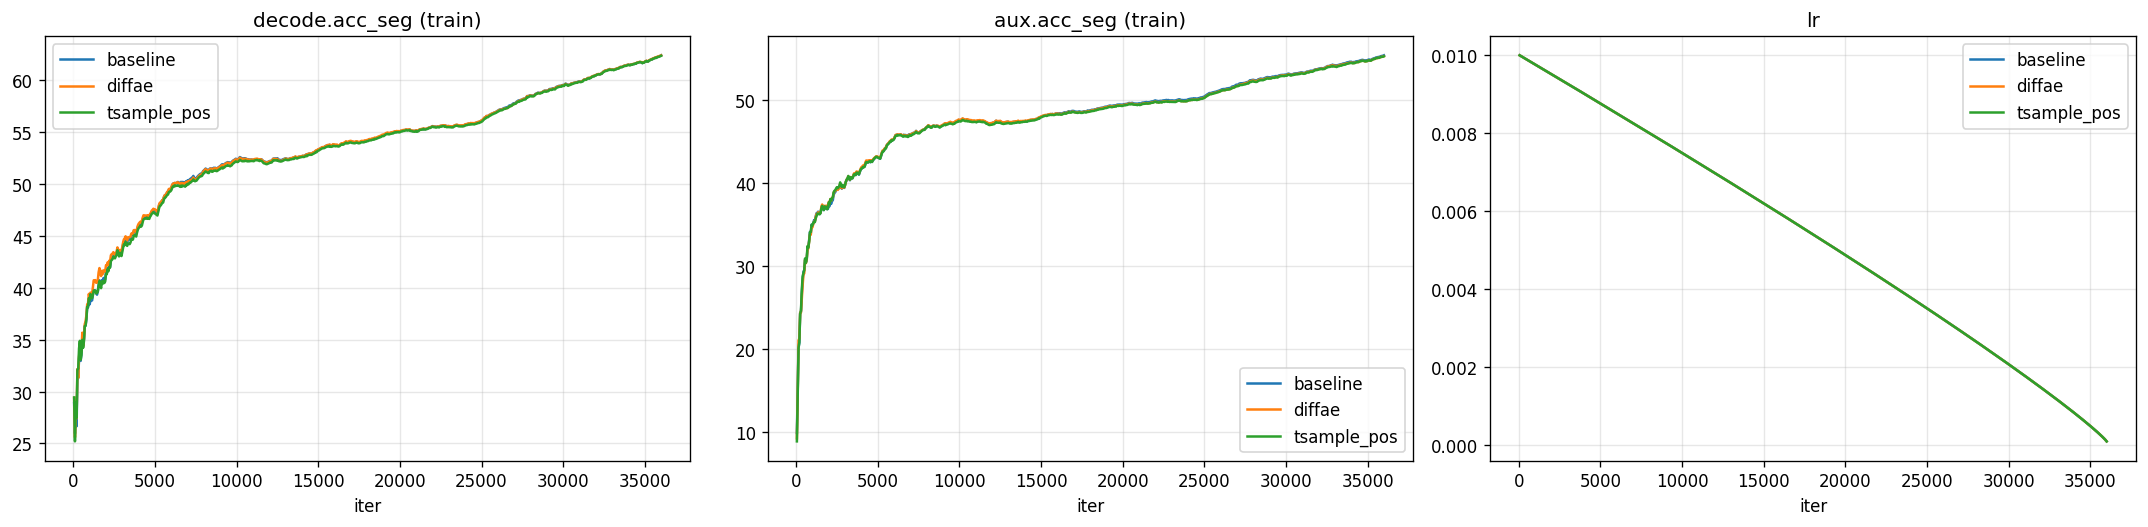

In [11]:
# ===================== train acc / lr =====================
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

for i, log in enumerate(all_logs):
    df = log['df']
    c = COLOR_CYCLE[i % len(COLOR_CYCLE)]
    if 'decode.acc_seg' in df.columns:
        axes[0].plot(df['iter'], smooth(df['decode.acc_seg']), color=c, label=log['label'])
    if 'aux.acc_seg' in df.columns:
        axes[1].plot(df['iter'], smooth(df['aux.acc_seg']), color=c, label=log['label'])
    if 'lr' in df.columns:
        axes[2].plot(df['iter'], df['lr'], color=c, label=log['label'])

axes[0].set_title('decode.acc_seg (train)')
axes[1].set_title('aux.acc_seg (train)')
axes[2].set_title('lr')
for ax in axes:
    ax.set_xlabel('iter')
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

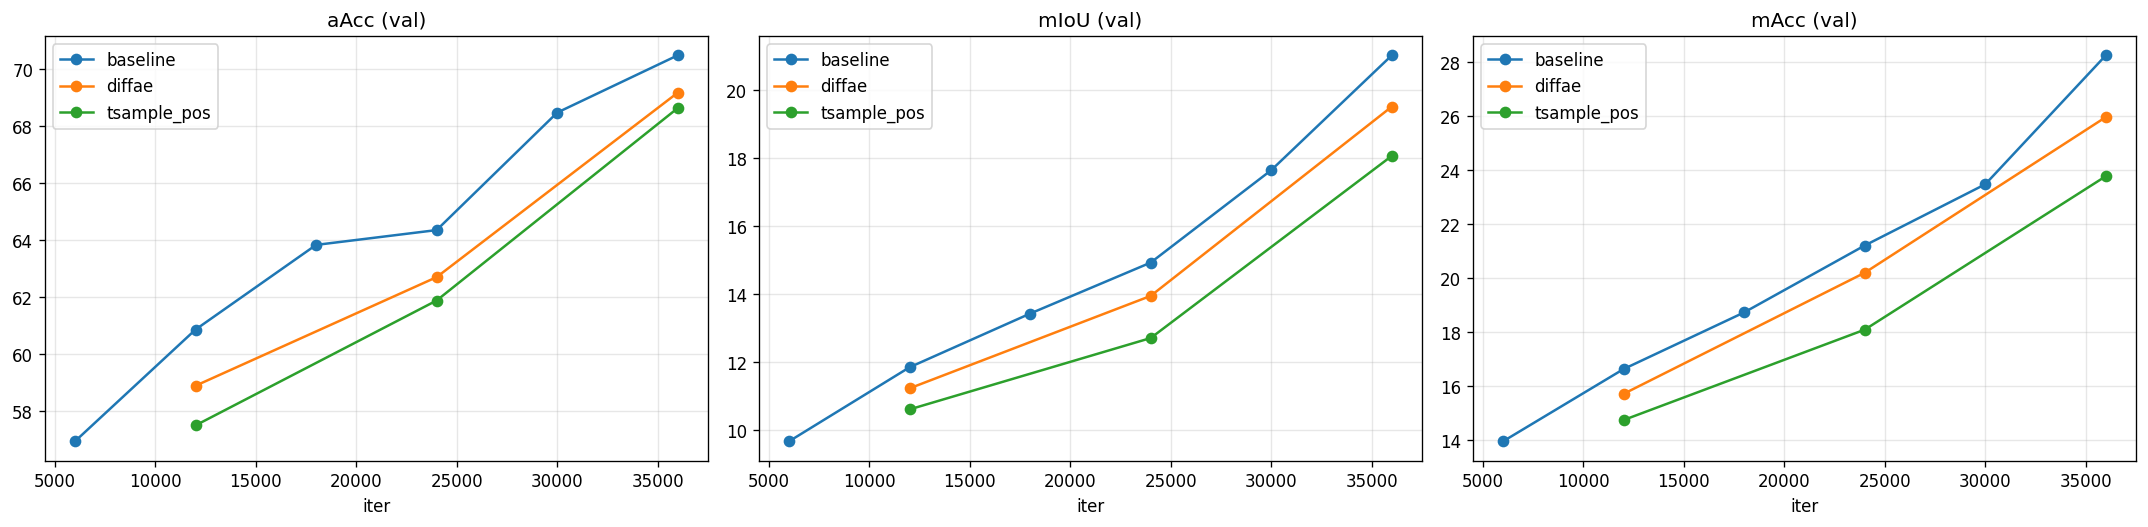


==== val 结果汇总（last = 最后一个验证点, best = 最优 mIoU）====
             last_aAcc  last_mIoU  last_mAcc  best_mIoU  best@iter
label                                                             
baseline         70.47      21.03      28.26      21.03      36000
diffae           69.16      19.52      25.97      19.52      36000
tsample_pos      68.62      18.07      23.78      18.07      36000


In [12]:
# ===================== val 指标 + 汇总表 =====================
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
val_panels = [('val_aAcc', 'aAcc (val)'), ('val_mIoU', 'mIoU (val)'), ('val_mAcc', 'mAcc (val)')]

summary_rows = []
for i, log in enumerate(all_logs):
    c = COLOR_CYCLE[i % len(COLOR_CYCLE)]
    for ax, (key, title) in zip(axes, val_panels):
        if len(log[key]) > 0:
            ax.plot(log['val_iters'], log[key], 'o-', color=c, label=log['label'])
    # 汇总：最后一个 val 点 + 最优 mIoU
    if len(log['val_mIoU']) > 0:
        best_idx = int(np.argmax(log['val_mIoU']))
        summary_rows.append({
            'label': log['label'],
            'last_aAcc': log['val_aAcc'][-1],
            'last_mIoU': log['val_mIoU'][-1],
            'last_mAcc': log['val_mAcc'][-1],
            'best_mIoU': log['val_mIoU'][best_idx],
            'best@iter': log['val_iters'][best_idx],
        })

for ax, (_, title) in zip(axes, val_panels):
    ax.set_title(title)
    ax.set_xlabel('iter')
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

summary = pd.DataFrame(summary_rows).set_index('label')
print("\n==== val 结果汇总（last = 最后一个验证点, best = 最优 mIoU）====")
print(summary.round(2))